# Ground Classification and Height Normalisation

## Workflow Overview

This notebook implements the ground classification and height normalisation workflow for ICP-aligned LiDAR tiles:

1. **Ground Classification (CSF)**: Cloth Simulation Filter (Zhang et al., 2016) to identify ground points
   - Parameters: resolution=0.5m, iterations=500, threshold=0.01m, rigidness=2
   - Output: Ground points classified as Class 2

2. **Height Normalisation (HAG)**: Inverse Distance Weighted (IDW) interpolation
   - k=3 nearest ground neighbours
   - Computes Height Above Ground (HAG) as Z - interpolated ground level
   - Stores as ExtraBytes dimension `Z_norm` (32-bit float)

CSF was selected over SMRF based on visual inspection, retaining more complete and spatially coherent ground points in areas of sparse vegetation.

In [5]:
# ============================================================
# Configuration and Imports
# ============================================================
from pathlib import Path
import sys

# Add parent directory to path to import groundnorm
sys.path.insert(0, str(Path.cwd().parent))

from groundnorm import run_csf_ground_filter, normalize_las_z
from groundnorm.dask_runner import process_batch_csf

import laspy
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from scipy.spatial import cKDTree
from matplotlib.colors import ListedColormap, BoundaryNorm, LinearSegmentedColormap
from matplotlib.cm import ScalarMappable
from mpl_toolkits.axes_grid1 import make_axes_locatable

# --- CONFIGURATION: Site 1 (DD0001) ---
SITE_NAME = "site2_1_DD0011"

INPUT_DIR = Path("/data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/coreg/icp")
OUTPUT_BASE = Path("/data/calperumResearch/site2_1_DD0011/lidar/clipped/raster")
AOI_RASTER_DIR = Path("/data/calperumResearch/site2_1_DD0011/imagery/inputs/predictors/tiles_3072/stacked")

GROUND_CSF_DIR = OUTPUT_BASE / "ground_classification" / "csf"
ZNORM_CSF_DIR = OUTPUT_BASE / "z_norm" / "csf"

for d in [GROUND_CSF_DIR, ZNORM_CSF_DIR]:
    d.mkdir(parents=True, exist_ok=True)

LAS_PATTERN = "tiles_multispectral*.las"

# Single tile for testing/inspection
TILE_ID = '33'

# CSF Parameters (Zhang et al., 2016)
CSF_RESOLUTION = 0.5      # Grid resolution (m)
CSF_ITERATIONS = 500      # Cloth simulation iterations
CSF_THRESHOLD = 0.01      # Height threshold (m)
CSF_RIGIDNESS = 2         # Cloth rigidness (1=low, 2=medium, 3=high)

# Height Normalisation Parameters
HAG_K_NEIGHBORS = 3       # Number of nearest ground neighbors for IDW interpolation

print("--- Configuration ---")
print(f"Site: {SITE_NAME}")
print(f"Input dir: {INPUT_DIR}")
print(f"Output base: {OUTPUT_BASE}")
print(f"Pattern: {LAS_PATTERN}")
print(f"Single tile ID: {TILE_ID}")
print(f"\nCSF Parameters:")
print(f"  Resolution: {CSF_RESOLUTION} m")
print(f"  Iterations: {CSF_ITERATIONS}")
print(f"  Threshold: {CSF_THRESHOLD} m")
print(f"  Rigidness: {CSF_RIGIDNESS}")
print(f"\nHAG Parameters:")
print(f"  k-nearest neighbors: {HAG_K_NEIGHBORS}")
print("---------------------")

--- Configuration ---
Site: site2_1_DD0011
Input dir: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/coreg/icp
Output base: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster
Pattern: tiles_multispectral*.las
Single tile ID: 33

CSF Parameters:
  Resolution: 0.5 m
  Iterations: 500
  Threshold: 0.01 m
  Rigidness: 2

HAG Parameters:
  k-nearest neighbors: 3
---------------------


In [6]:
# --- Find LAS files to process ---
las_files = sorted(INPUT_DIR.glob(LAS_PATTERN))

if not las_files:
    print(f"❌ No LAS files found in {INPUT_DIR}")
else:
    print(f"Found {len(las_files)} LAS files to process")
    print("\nFirst 5 files:")
    for f in las_files[:5]:
        print(f"  {f.name}")
    
    # Inspect first file
    if las_files:
        sample = las_files[0]
        las = laspy.read(sample)
        print(f"\nSample file: {sample.name}")
        print(f"  Points: {len(las.points):,}")
        print(f"  Bounds:")
        print(f"    X: {las.header.mins[0]:.2f} → {las.header.maxs[0]:.2f}")
        print(f"    Y: {las.header.mins[1]:.2f} → {las.header.maxs[1]:.2f}")
        print(f"    Z: {las.header.mins[2]:.2f} → {las.header.maxs[2]:.2f}")

Found 15 LAS files to process

First 5 files:
  tiles_multispectral.25.las
  tiles_multispectral.30.las
  tiles_multispectral.31.las
  tiles_multispectral.33.las
  tiles_multispectral.39.las

Sample file: tiles_multispectral.25.las
  Points: 823,683
  Bounds:
    X: 473284.76 → 473315.53
    Y: 6235833.51 → 6235864.27
    Z: 32.53 → 34.22


## Single Tile Processing (Testing)

Process one tile to validate the workflow before batch processing.

In [7]:
# --- Process single tile (for testing) ---
# Use configured TILE_ID to process specific tile
test_tile = INPUT_DIR / f"tiles_multispectral.{TILE_ID}.las"

if not test_tile.exists():
    print(f"❌ Tile not found: {test_tile}")
    print(f"   Looking for first available tile instead...")
    if las_files:
        test_tile = las_files[0]
        print(f"   Using: {test_tile.name}")
    else:
        raise FileNotFoundError(f"No LAS files found in {INPUT_DIR}")
else:
    print(f"✅ Found tile: {test_tile.name}")

tile_name = test_tile.stem

print(f"\nProcessing test tile: {tile_name}")

# Step 1: CSF Ground Classification
csf_ground = GROUND_CSF_DIR / f"csf_{tile_name}.las"
print("\n=== Step 1: CSF Ground Classification ===")
print(f"Parameters: resolution={CSF_RESOLUTION}, iterations={CSF_ITERATIONS}, threshold={CSF_THRESHOLD}, rigidness={CSF_RIGIDNESS}")
run_csf_ground_filter(
    input_las=test_tile,
    output_las=csf_ground,
    resolution=CSF_RESOLUTION,
    iterations=CSF_ITERATIONS,
    threshold=CSF_THRESHOLD,
    rigidness=CSF_RIGIDNESS,
)

# Step 2: Z Normalization (HAG calculation)
znorm_csf = ZNORM_CSF_DIR / f"z_norm_csf_{tile_name}.las"
print(f"\n=== Step 2: Height Normalisation (HAG) ===")
print(f"Parameters: k={HAG_K_NEIGHBORS} (IDW interpolation)")
normalize_las_z(
    input_las=test_tile,
    ground_las=csf_ground,
    output_las=znorm_csf,
    k=HAG_K_NEIGHBORS,
    extra_dim_name="Z_norm",
)

print("\n✅ Test tile processing complete!")
print(f"   Ground points: {csf_ground}")
print(f"   Normalised HAG: {znorm_csf}")

✅ Found tile: tiles_multispectral.33.las

Processing test tile: tiles_multispectral.33

=== Step 1: CSF Ground Classification ===
Parameters: resolution=0.5, iterations=500, threshold=0.01, rigidness=2
💾 Saved PDAL CSF pipeline: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/ground_classification/csf/csf_tiles_multispectral.33.json
▶️  Running PDAL CSF on tiles_multispectral.33.las


(PDAL Debug) Debugging...
(pdal pipeline Debug) Executing pipeline in standard mode.
(pdal pipeline filters.csf Debug) setPointCloud: 1647714
(pdal pipeline filters.csf Debug) [0] Configuring terrain...
(pdal pipeline filters.csf Debug) 473285, 473254
(pdal pipeline filters.csf Debug) [0] Configuring cloth...
(pdal pipeline filters.csf Debug) [0]  - width: 65 height: 65
(pdal pipeline filters.csf Debug) [0] Rasterizing...
(pdal pipeline filters.csf Debug) [0] Simulating...
(pdal pipeline writers.las Debug) Wrote 561744 points to the LAS file


✅ CSF ground LAS: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/ground_classification/csf/csf_tiles_multispectral.33.las

=== Step 2: Height Normalisation (HAG) ===
Parameters: k=3 (IDW interpolation)
✅ Wrote normalized LAS: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/z_norm/csf/z_norm_csf_tiles_multispectral.33.las
   HAG stats (m): min=0.000, median=0.007, max=6.593
   Ground pts: 561,744, All pts: 1,666,642, k=3

✅ Test tile processing complete!
   Ground points: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/ground_classification/csf/csf_tiles_multispectral.33.las
   Normalised HAG: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/z_norm/csf/z_norm_csf_tiles_multispectral.33.las


## Validation Visualization

Visualize ground classification results and HAG values.

✅ Visualizing tile: tiles_multispectral.33


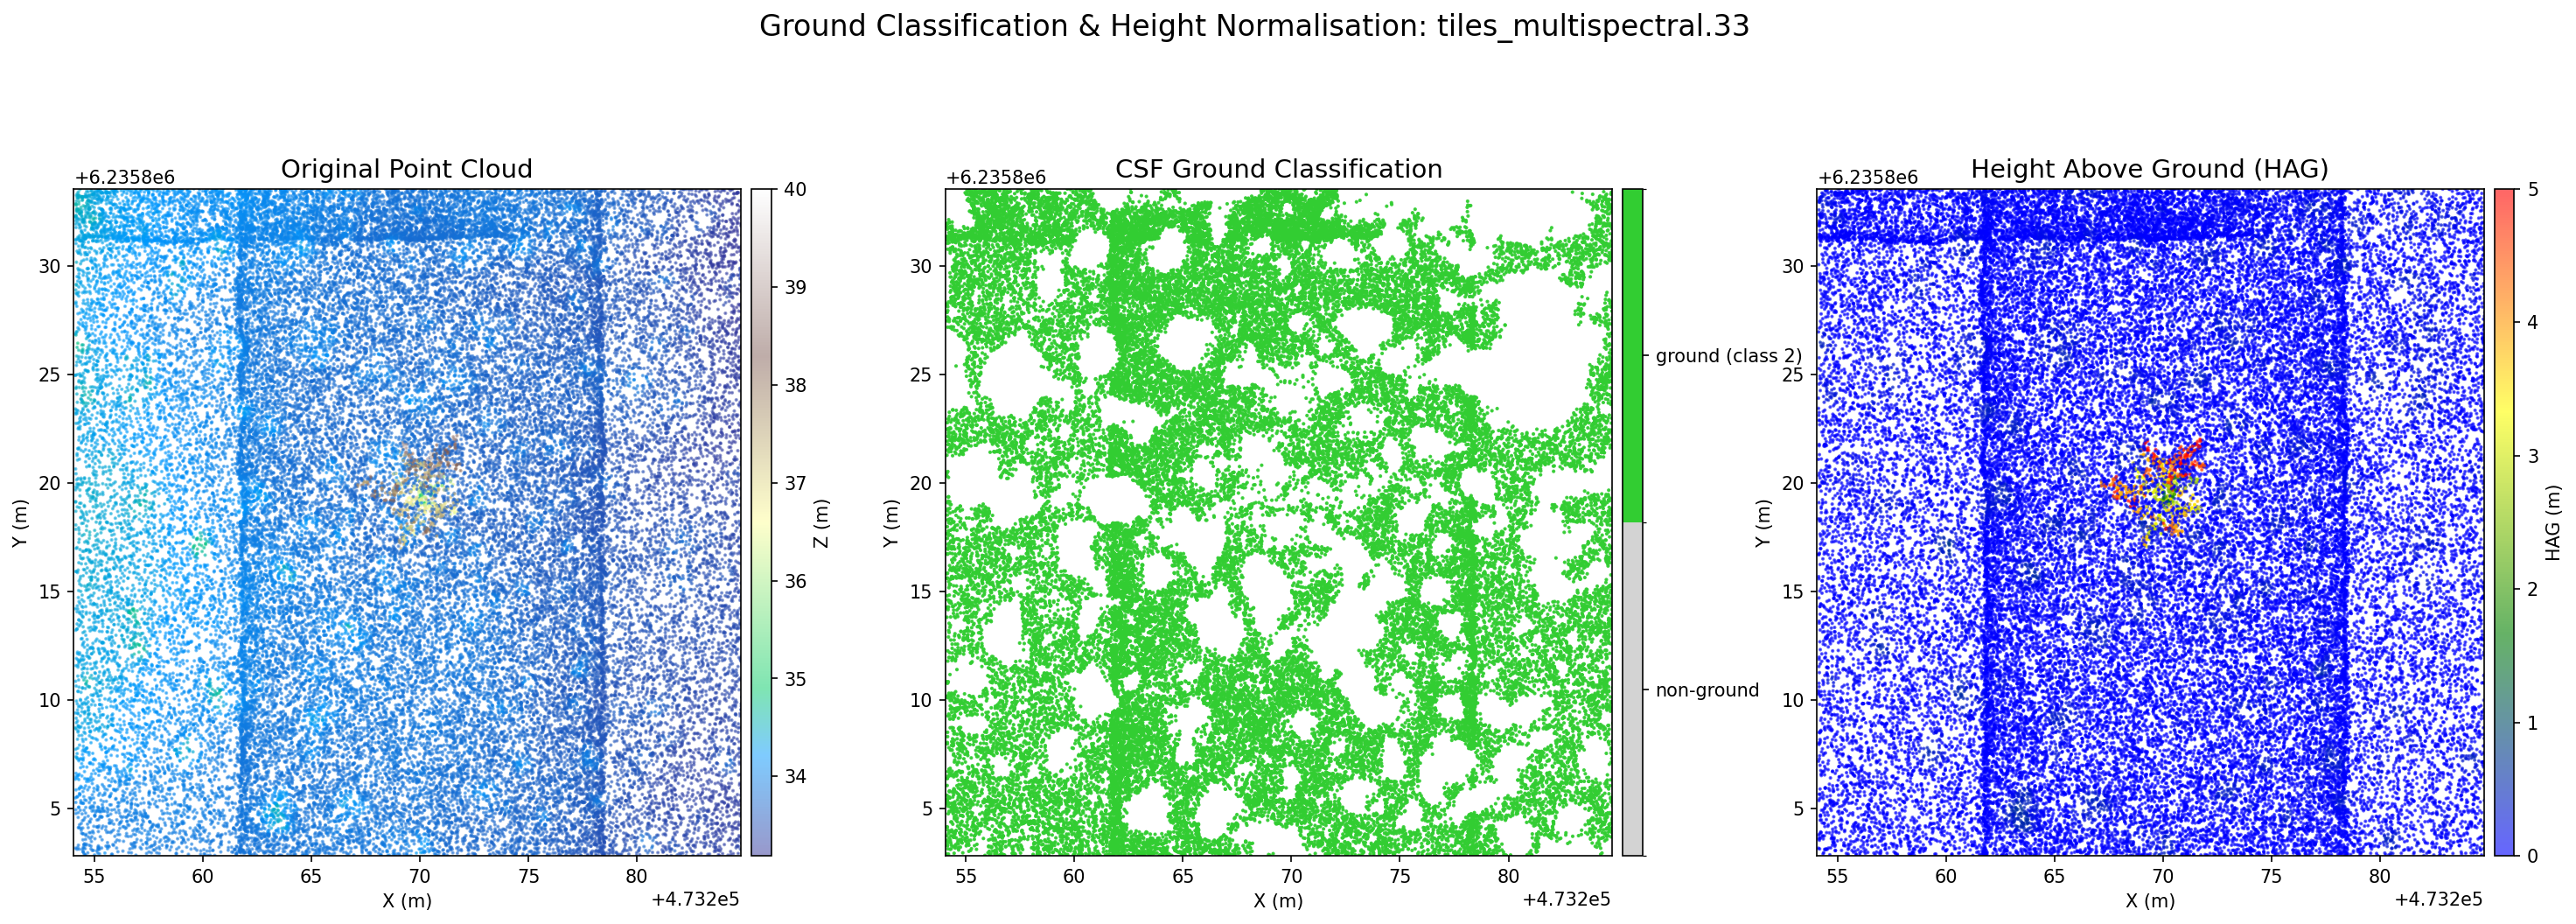


=== HAG Statistics ===
Min: 0.000 m
Mean: 0.086 m
Median: 0.007 m
Max: 6.593 m
Std: 0.451 m


In [8]:
# --- Visualization: Original + CSF Ground + HAG ---
# Set specific tile ID for visualization (or use test_tile from previous cell)
TILE_ID = '33'

# Load specific tile if TILE_ID is set, otherwise use test_tile from previous cell
if TILE_ID:
    test_tile = INPUT_DIR / f"tiles_multispectral.{TILE_ID}.las"
    tile_name = test_tile.stem
    csf_ground = GROUND_CSF_DIR / f"csf_{tile_name}.las"
    znorm_csf = ZNORM_CSF_DIR / f"z_norm_csf_{tile_name}.las"
    
    if not test_tile.exists():
        print(f"⚠️ Warning: Tile {TILE_ID} not found at {test_tile}")
        print("   Using test_tile from previous cell instead...")
    elif not csf_ground.exists() or not znorm_csf.exists():
        print(f"⚠️ Warning: Processed outputs for tile {TILE_ID} not found")
        print(f"   CSF ground exists: {csf_ground.exists()}")
        print(f"   Z-norm exists: {znorm_csf.exists()}")
        print("   Run processing cell first or use test_tile from previous cell")
    else:
        print(f"✅ Visualizing tile: {tile_name}")

max_pts = 50000

def downsample_idx(n: int, max_pts: int) -> np.ndarray:
    if n > max_pts:
        return np.random.choice(n, size=max_pts, replace=False)
    return np.arange(n)

# Load data
las_orig = laspy.read(test_tile)
las_csf_ground = laspy.read(csf_ground)
las_znorm = laspy.read(znorm_csf)

# Get extent from multispectral raster tile
tile_id = test_tile.stem.split('.')[-1]
raster_extent_path = AOI_RASTER_DIR / f'tiles_multispectral.{tile_id}.tif'
if raster_extent_path.exists():
    with rasterio.open(raster_extent_path) as src:
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)
else:
    extent = None
    print(f"⚠️ Warning: Raster tile not found at {raster_extent_path}")

# Extract data for original
idx0 = downsample_idx(len(las_orig.points), max_pts)
x_orig = las_orig.x[idx0]
y_orig = las_orig.y[idx0]
z_orig = las_orig.z[idx0]

# Extract data for ground classification
x_csf = np.asarray(las_csf_ground.x)
y_csf = np.asarray(las_csf_ground.y)
cls_csf = np.asarray(las_csf_ground.classification)
idx1 = downsample_idx(len(x_csf), max_pts)
x_csf, y_csf, cls_csf = x_csf[idx1], y_csf[idx1], cls_csf[idx1]

# Extract HAG
z_norm = np.asarray(las_znorm.Z_norm, dtype=np.float32)
idx2 = downsample_idx(len(z_norm), max_pts)
x_hag = las_znorm.x[idx2]
y_hag = las_znorm.y[idx2]
hag = z_norm[idx2]

# Create figure
fig, axes = plt.subplots(1, 3, figsize=(24, 8), dpi=150)
fig.subplots_adjust(wspace=0.25)

# (1) Original point cloud (Z-colored)
ax = axes[0]
sc0 = ax.scatter(x_orig, y_orig, s=1, c=z_orig, cmap='terrain', alpha=0.5)
ax.set_title('Original Point Cloud', fontsize=14)
ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_aspect('equal')
if extent:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
divider0 = make_axes_locatable(ax)
cax0 = divider0.append_axes("right", size="3%", pad=0.08)
cbar0 = fig.colorbar(sc0, cax=cax0)
cbar0.set_label('Z (m)')

# (2) CSF ground classification
ax = axes[1]
is_ground = (cls_csf == 2).astype(np.uint8)
class_cmap = ListedColormap(["lightgray", "limegreen"])
class_norm = BoundaryNorm([0, 0.5, 1.0], class_cmap.N)
sc1 = ax.scatter(x_csf, y_csf, s=1, c=is_ground, cmap=class_cmap, norm=class_norm, alpha=0.9)
ax.set_title('CSF Ground Classification', fontsize=14)
ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_aspect('equal')
if extent:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
divider1 = make_axes_locatable(ax)
cax1 = divider1.append_axes("right", size="3%", pad=0.08)
class_mappable = ScalarMappable(cmap=class_cmap, norm=class_norm)
class_mappable.set_array([])
cbar1 = fig.colorbar(class_mappable, cax=cax1)
cbar1.set_ticks([0.25, 0.75])
cbar1.set_ticklabels(["non-ground", "ground (class 2)"])

# (3) Height Above Ground (HAG)
ax = axes[2]
colors_bgyr = ['blue', 'green', 'yellow', 'red']
cmap_bgyr = LinearSegmentedColormap.from_list('bgyr', colors_bgyr, N=256)
sc2 = ax.scatter(x_hag, y_hag, s=1, c=hag, cmap=cmap_bgyr, alpha=0.6, vmin=0, vmax=5)
ax.set_title('Height Above Ground (HAG)', fontsize=14)
ax.set_xlabel('X (m)')
ax.set_ylabel('Y (m)')
ax.set_aspect('equal')
if extent:
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
divider2 = make_axes_locatable(ax)
cax2 = divider2.append_axes("right", size="3%", pad=0.08)
cbar2 = fig.colorbar(sc2, cax=cax2)
cbar2.set_label('HAG (m)')

plt.suptitle(f'Ground Classification & Height Normalisation: {tile_name}', fontsize=16, y=0.98)
plt.show()

# Statistics
print("\n=== HAG Statistics ===")
print(f"Min: {z_norm.min():.3f} m")
print(f"Mean: {z_norm.mean():.3f} m")
print(f"Median: {np.median(z_norm):.3f} m")
print(f"Max: {z_norm.max():.3f} m")
print(f"Std: {z_norm.std():.3f} m")

## Batch Processing

Process all LAS tiles in parallel using Dask.

In [9]:
# --- Batch process all tiles ---
# Process multiple tiles in parallel using Dask

print("Starting batch processing...")
print(f"Input: {INPUT_DIR}")
print(f"Pattern: {LAS_PATTERN}")
print(f"Files found: {len(list(INPUT_DIR.glob(LAS_PATTERN)))}")
print("\nProcessing with CSF + Height Normalisation...")

process_batch_csf(
    input_dir=INPUT_DIR,
    output_base=OUTPUT_BASE,
    pattern=LAS_PATTERN,
    normalize=True,  # Enable height normalisation
    n_workers=4,     # Adjust based on available CPU cores
    resolution=CSF_RESOLUTION,
    iterations=CSF_ITERATIONS,
    threshold=CSF_THRESHOLD,
    rigidness=CSF_RIGIDNESS,
)

print("\n✅ Batch processing complete!")
print(f"   Ground points: {GROUND_CSF_DIR}")
print(f"   Normalised HAG: {ZNORM_CSF_DIR}")

Starting batch processing...
Input: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/coreg/icp
Pattern: tiles_multispectral*.las
Files found: 15

Processing with CSF + Height Normalisation...
Found 15 LAS files to process with CSF
Using 4 workers


CSF processing: 100%|██████████| 15/15 [00:00<00:00, 4656.20it/s]

✅ tiles_multispectral.31
✅ tiles_multispectral.43
✅ tiles_multispectral.25
✅ tiles_multispectral.30
✅ tiles_multispectral.39
✅ tiles_multispectral.41
✅ tiles_multispectral.48
✅ tiles_multispectral.33
✅ tiles_multispectral.52
✅ tiles_multispectral.60
✅ tiles_multispectral.58
✅ tiles_multispectral.66
✅ tiles_multispectral.68
✅ tiles_multispectral.75
✅ tiles_multispectral.79

🎉 CSF processing complete!

✅ Batch processing complete!
   Ground points: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/ground_classification/csf
   Normalised HAG: /data/calperumResearch/site2_1_DD0011/lidar/clipped/raster/z_norm/csf


## Summary

This workflow implements:

1. **CSF Ground Classification** (Zhang et al., 2016)
   - Cloth simulation with 0.5m grid resolution
   - 500 iterations for terrain adaptation
   - 0.01m height threshold for ground/non-ground separation
   - Medium rigidness (2) for heterogeneous vegetation

2. **Height Normalisation (HAG)**
   - IDW interpolation using k=3 nearest ground neighbors
   - Stores HAG as `Z_norm` ExtraBytes dimension
   - Negative values clamped to zero

**Outputs:**
- Ground classification: `{GROUND_CSF_DIR}/csf_*.las` (Class 2 = ground)
- Height normalised: `{ZNORM_CSF_DIR}/z_norm_csf_*.las` (with Z_norm dimension)

**Quality Control:**
- Visual inspection confirmed CSF provides more complete ground coverage
- Spatial coherence maintained in sparse vegetation areas
- Original LAS quantisation preserved (scale/offset/metadata)